# Stage 3: Quantitative Gait Analysis

## Objective
Analyze a sagittal-plane walking video using MoveNet to extract hip, knee, and ankle keypoints, estimate joint angles, and study their changes over time.

## Workflow
1. Inspect and validate the video.
2. Visualize frames and verify the camera view.
3. Extract pose keypoints using MoveNet.
4. Calculate hip, knee, and ankle angles.
5. Visualize joint angles over time.
6. Evaluate prediction reliability and limitations.

**Input video:** `data/raw/sagittal_walking.mp4`

## Exercise 1: Video Metadata

Inspect the video's frame rate, frame count, resolution, and duration. These properties help us understand the temporal and spatial characteristics of our input data.

In [5]:
from pathlib import Path
import cv2

project_root = Path.cwd().parent
video_path = project_root / "data" / "raw" / "sagittal_walking.mp4"

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# TODO: Get the video's width and height.
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# TODO: Calculate duration in seconds.
duration = frame_count / fps

print(f"Resolution: {width} x {height}")
print(f"FPS: {fps}")
print(f"Frame count: {frame_count}")
print(f"Duration: {duration:.2f} seconds")

cap.release()

Resolution: 1920 x 1080
FPS: 30.0
Frame count: 406
Duration: 13.53 seconds


## Exercise 2: Visual Video Inspection

Visualize representative frames to check the camera angle, body visibility, and suitability of the video for sagittal-plane gait analysis.

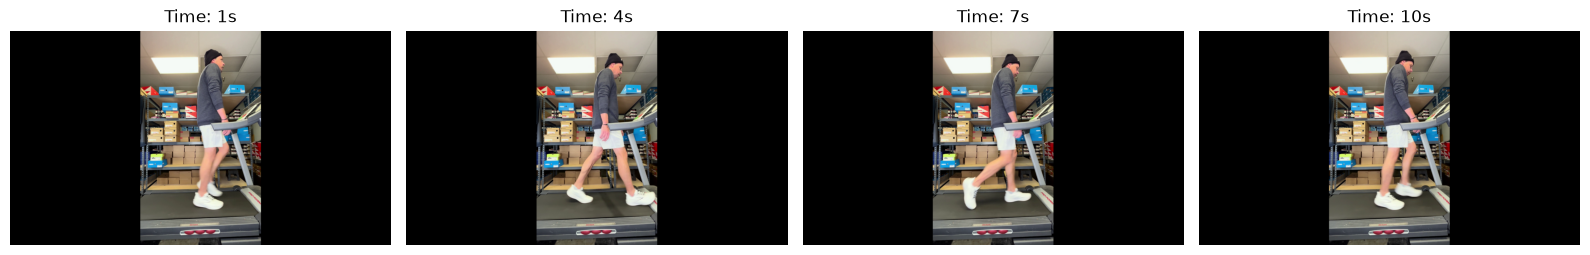

In [6]:
cap = cv2.VideoCapture(str(video_path))

timestamps = [1, 4, 7, 10]
frames_rgb = []

for t in timestamps:
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_rgb.append((t, frame_rgb))

cap.release()

fig, axes = plt.subplots(1, len(frames_rgb), figsize=(16, 5))

for ax, (t, frame) in zip(axes, frames_rgb):
    ax.imshow(frame)
    ax.set_title(f"Time: {t}s")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Exercise 3: Frame Sampling and Visibility

Extract representative frames from the walking video and inspect whether the lower-body keypoints are visible throughout the gait cycle. Pay particular attention to leg overlap and occlusion.

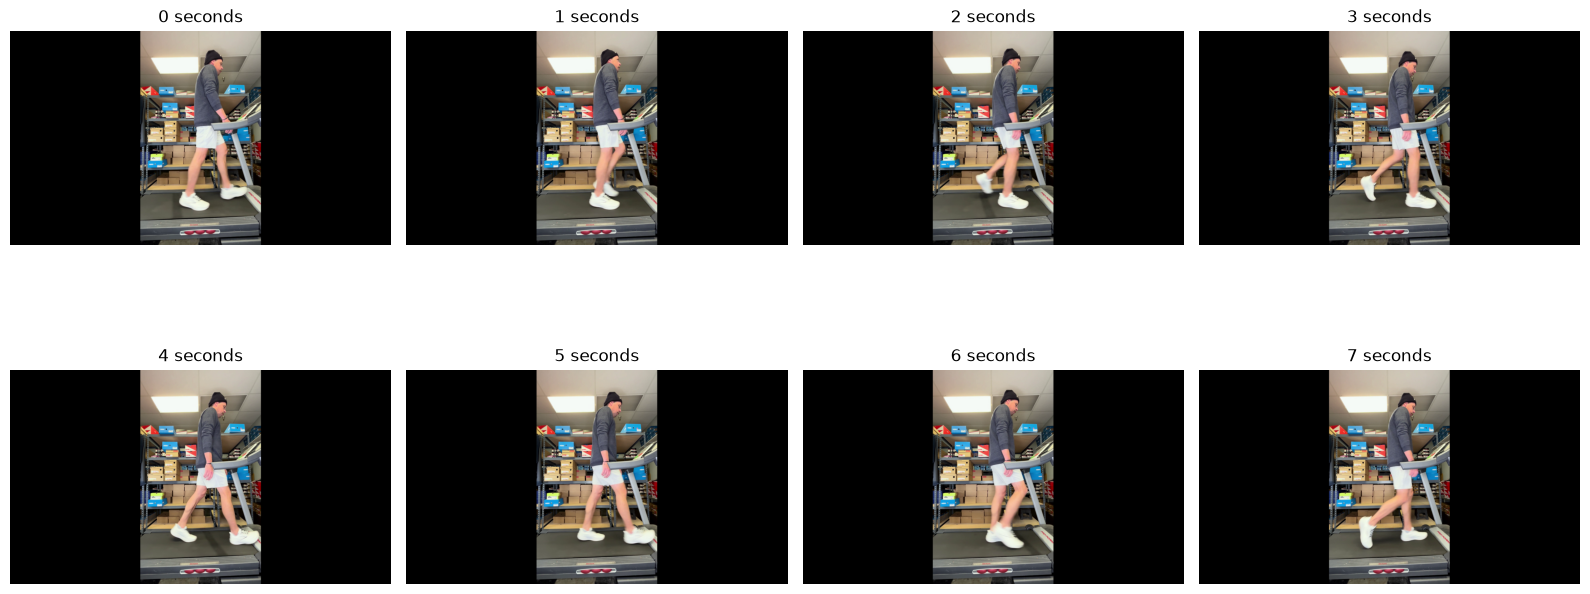

In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Sample one frame every second.
timestamps = np.arange(0, frame_count / fps, 1.0)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, t in zip(axes, timestamps[:8]):
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame_rgb)
        ax.set_title(f"{t:.0f} seconds")
    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

## Exercise 4: Pose Estimation on the Walking Video

Run MoveNet on sampled video frames to extract body keypoints. We will use these predictions to estimate lower-body joint angles and analyze their changes over time.

In [12]:
from ai_edge_litert.interpreter import Interpreter

def predict_pose_letterboxed(frame, input_details, output_details, interpreter):
    """
    Run MoveNet inference on a frame using letterbox preprocessing.

    Returns:
        keypoints_original: (17, 3) array containing
            [normalized_y_original, normalized_x_original, confidence]

        keypoints_model: (17, 3) array containing the original
            normalized model predictions [y, x, confidence]
    """

    # 1. Convert BGR to RGB
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # 2. Get the original image dimensions
    image_height, image_width = frame_rgb.shape[:2]

    # 3. Get the model input dimensions
    input_shape = input_details[0]["shape"]
    input_height = int(input_shape[1])
    input_width = int(input_shape[2])

    # 4. Calculate the aspect-ratio-preserving scale
    scale = min(
        input_width / image_width,
        input_height / image_height
    )

    # 5. Calculate resized dimensions
    resized_width = int(round(image_width * scale))
    resized_height = int(round(image_height * scale))

    # 6. Resize the frame
    resized_content = cv2.resize(
        frame_rgb,
        (resized_width, resized_height),
        interpolation=cv2.INTER_LINEAR
    )

    # 7. Calculate padding
    pad_left = (input_width - resized_width) // 2
    pad_top = (input_height - resized_height) // 2

    # 8. Create the model input canvas
    resized_frame = np.zeros(
        (input_height, input_width, 3),
        dtype=np.uint8
    )

    # 9. Place the resized image inside the canvas
    resized_frame[
        pad_top:pad_top + resized_height,
        pad_left:pad_left + resized_width
    ] = resized_content

    # 10. Add the batch dimension
    model_input = np.expand_dims(resized_frame, axis=0)

    # 11. Match the model's expected input data type
    input_dtype = input_details[0]["dtype"]

    if input_dtype == np.uint8:
        model_input = model_input.astype(np.uint8)
    elif input_dtype == np.float32:
        model_input = model_input.astype(np.float32)
    else:
        raise TypeError(
            f"Unexpected model input dtype: {input_dtype}"
        )

    # 12. Run MoveNet inference
    interpreter.set_tensor(
        input_details[0]["index"],
        model_input
    )

    interpreter.invoke()

    raw_output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    keypoints_model = np.squeeze(raw_output).copy()

    if keypoints_model.shape != (17, 3):
        raise ValueError(
            f"Expected (17, 3), got {keypoints_model.shape}"
        )

    # 13. Convert normalized model coordinates to model pixels
    keypoints_original = keypoints_model.copy()

    x_model = keypoints_model[:, 1] * input_width
    y_model = keypoints_model[:, 0] * input_height

    # 14. Remove padding and reverse the resizing
    x_original = (x_model - pad_left) / scale
    y_original = (y_model - pad_top) / scale

    # 15. Normalize coordinates relative to the original image
    keypoints_original[:, 1] = x_original / image_width
    keypoints_original[:, 0] = y_original / image_height

    return keypoints_original, keypoints_model

In [14]:
model_path = project_root / "models" / "movenet_lightning.tflite"

if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path}")

interpreter = Interpreter(
    model_path=str(model_path),
    num_threads=4
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Model loaded successfully!")
print("\nInput details:")
for item in input_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

print("\nOutput details:")
for item in output_details:
    print({
        "shape": item["shape"].tolist(),
        "dtype": str(item["dtype"]),
        "name": item["name"],
    })

Model loaded successfully!

Input details:
{'shape': [1, 192, 192, 3], 'dtype': "<class 'numpy.uint8'>", 'name': 'serving_default_input:0'}

Output details:
{'shape': [1, 1, 17, 3], 'dtype': "<class 'numpy.float32'>", 'name': 'StatefulPartitionedCall:0'}


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [19]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Failed to open video:", video_path)

arr_keypoints_original = []
arr_keypoints_model = []

for index in range(frame_count):
    ret, frame = cap.read()

    if not ret:
        continue
    if index % 5 == 0:
        keypoints_original, keypoints_model = predict_pose_letterboxed(frame, input_details, output_details, interpreter)
        arr_keypoints_original.append({
            "frame_index" : index,
            "timestamp" : index / fps,
            "keypoints" : keypoints_original
        })
        arr_keypoints_model.append({
            "frame_index" : index,
            "timestamp" : index / fps,
            "keypoints" : keypoints_model
        })

cap.release()

print(arr_keypoints_model[3])

{'frame_index': 15, 'timestamp': 0.5, 'keypoints': array([[0.3153335 , 0.543738  , 0.6820467 ],
       [0.3090665 , 0.5476605 , 0.58184284],
       [0.3077379 , 0.5392186 , 0.6038437 ],
       [0.31124294, 0.5381745 , 0.40366477],
       [0.30671772, 0.52016664, 0.55421454],
       [0.33720198, 0.5253136 , 0.5239111 ],
       [0.33095893, 0.518314  , 0.43525535],
       [0.39966014, 0.52419746, 0.37086484],
       [0.39386836, 0.52273965, 0.3468447 ],
       [0.43042278, 0.52833575, 0.41737837],
       [0.42837247, 0.5281514 , 0.43364847],
       [0.4840112 , 0.5072699 , 0.4531568 ],
       [0.48132822, 0.5133184 , 0.41893315],
       [0.54302037, 0.5391383 , 0.24295725],
       [0.5349776 , 0.56210643, 0.4729598 ],
       [0.64233255, 0.5378606 , 0.38143933],
       [0.6365219 , 0.5498016 , 0.4502868 ]], dtype=float32)}
